Chapter: Ensemble Learning <br>
Dataset: Bank 

---

In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

---

Section 01: Preprocess Bank dataset

In [4]:
df = pd.read_csv("bank.csv")
df

,no,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,1,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,2,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,3,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,4,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,5,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,45207,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,45208,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,45209,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,45210,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


In [5]:
from sklearn.preprocessing import MinMaxScaler

#---------- Integer ----------#
cols = ['age', 'balance', 'day', 'duration', 'campaign', 'pdays', 'previous']
df[cols] = MinMaxScaler().fit_transform(df[cols])


#---------- binary ----------#
for col in ['default', 'housing', 'loan', 'y']:
    df[col] = df[col].map({'no':0, 'yes':1})


#---------- one-hot encoding ----------#
df = pd.get_dummies(
    df,
    columns=['job', 'marital', 'education', 'contact', 'poutcome', 'month'],
    dtype=int
)

df

,no,age,default,balance,housing,loan,day,duration,campaign,pdays,...,month_dec,month_feb,month_jan,month_jul,month_jun,month_mar,month_may,month_nov,month_oct,month_sep
0,1,0.519481,0,0.092259,1,0,0.133333,0.053070,0.000000,0.000000,...,0,0,0,0,0,0,1,0,0,0
1,2,0.337662,0,0.073067,1,0,0.133333,0.030704,0.000000,0.000000,...,0,0,0,0,0,0,1,0,0,0
2,3,0.194805,0,0.072822,1,1,0.133333,0.015453,0.000000,0.000000,...,0,0,0,0,0,0,1,0,0,0
3,4,0.376623,0,0.086476,1,0,0.133333,0.018707,0.000000,0.000000,...,0,0,0,0,0,0,1,0,0,0
4,5,0.194805,0,0.072812,0,0,0.133333,0.040260,0.000000,0.000000,...,0,0,0,0,0,0,1,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,45207,0.428571,0,0.080293,0,0,0.533333,0.198658,0.032258,0.000000,...,0,0,0,0,0,0,0,1,0,0
45207,45208,0.688312,0,0.088501,0,0,0.533333,0.092721,0.016129,0.000000,...,0,0,0,0,0,0,0,1,0,0
45208,45209,0.701299,0,0.124689,0,0,0.533333,0.229158,0.064516,0.212156,...,0,0,0,0,0,0,0,1,0,0
45209,45210,0.506494,0,0.078868,0,0,0.533333,0.103294,0.048387,0.000000,...,0,0,0,0,0,0,0,1,0,0


In [6]:
df.to_csv("bank_pre.csv", index=False)

---

Section 02: Separate training data and Test data

In [7]:
from sklearn.model_selection import train_test_split

# Load data
df = pd.read_csv('bank_pre.csv')

# Split X, y
X = df.drop(columns='y')
y = df['y']

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print('X_train:', X_train.shape)
print('X_test :', X_test.shape)
print('y_train:', y_train.shape)
print('y_test :', y_test.shape)

pd.DataFrame({
    'Original (%)': y.value_counts(normalize=True) * 100,
    'Train (%)': y_train.value_counts(normalize=True) * 100,
    'Test (%)': y_test.value_counts(normalize=True) * 100
}).sort_index()


X_train: (36168, 49)
X_test : (9043, 49)
y_train: (36168,)
y_test : (9043,)


,Original (%),Train (%),Test (%)
y,,,
0,88.30152,88.301814,88.300343
1,11.69848,11.698186,11.699657


In [8]:
# Save files
X_train.to_csv('X_train.csv', index=False)
X_test.to_csv('X_test.csv', index=False)

y_train.to_csv('y_train.csv', index=False)
y_test.to_csv('y_test.csv', index=False)

---

Section 03: Decision Tree (Benchmark)

Best Parameters
{'max_depth': 3, 'min_samples_leaf': 1, 'min_samples_split': 2}
Best CV F1 Score: 0.5853

===== Test Result =====
Accuracy  : 0.9030
Precision : 0.5874
Recall    : 0.5747
F1-Score  : 0.5810


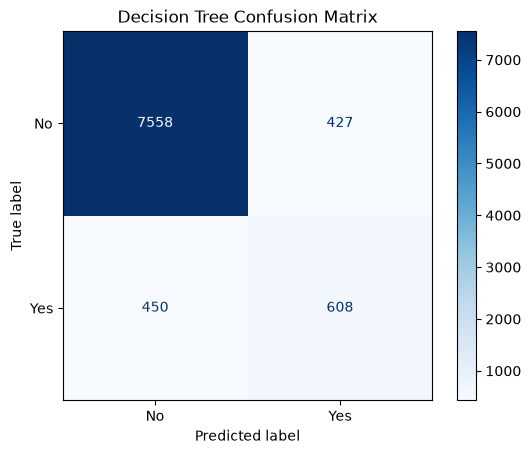

In [9]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

#---------- Load data ----------#
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')
y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()



#---------- Parameter tuning ----------#
param_grid = {
    'max_depth': [3, 5, 7, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid = GridSearchCV(
    estimator=DecisionTreeClassifier(criterion='gini', random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_dt = grid.best_estimator_

print("Best Parameters")
print(grid.best_params_)
print(f"Best CV F1 Score: {grid.best_score_:.4f}")



#---------- Predict ----------#
y_pred = best_dt.predict(X_test)

# Metrics
print("\n===== Test Result =====")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

cm = confusion_matrix(y_test, y_pred)
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)
disp.plot(cmap='Blues')
plt.title('Decision Tree Confusion Matrix')
plt.show()

---

Section 05 : Random Forest

Best Parameters
{'max_depth': None, 'min_samples_leaf': 1, 'min_samples_split': 10, 'n_estimators': 200}
Best CV F1 Score: 0.5597

===== Test Result =====
Accuracy  : 0.9144
Precision : 0.6983
Recall    : 0.4726
F1-Score  : 0.5637


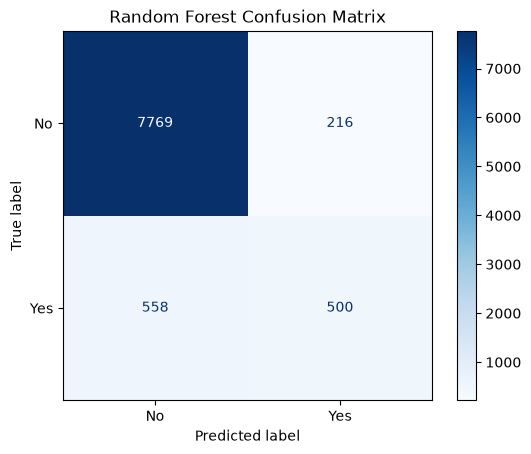

In [10]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


#---------- Load data ----------#
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

#---------- Parameter tuning ----------#
param_grid = {
    'n_estimators': [50, 100, 200],
    'max_depth': [3, 5, 10, None],
    'min_samples_split': [2, 5, 10],
    'min_samples_leaf': [1, 2, 5]
}

grid = GridSearchCV(
    estimator=RandomForestClassifier(random_state=42),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_rf = grid.best_estimator_

print("Best Parameters")
print(grid.best_params_)

print(f"Best CV F1 Score: {grid.best_score_:.4f}")

#---------- Predict ----------#
y_pred = best_rf.predict(X_test)

# Metrics
print("\n===== Test Result =====")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

#---------- Confusion Matrix ----------#
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.title('Random Forest Confusion Matrix')
plt.show()

---

Section 06: AdaBoost

Best Parameters
{'learning_rate': 1.0, 'n_estimators': 200}
Best CV F1 Score: 0.4810

===== Test Result =====
Accuracy  : 0.9037
Precision : 0.6506
Recall    : 0.3819
F1-Score  : 0.4812


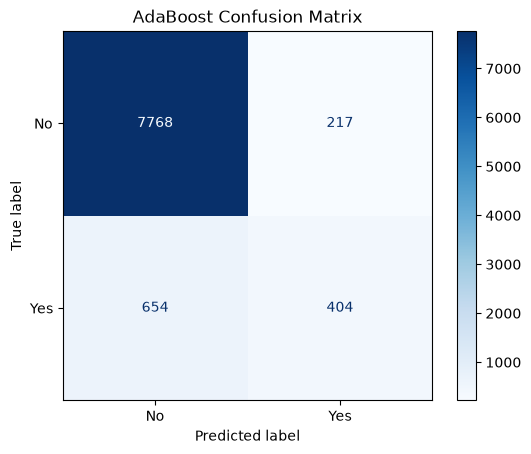

In [11]:
from sklearn.ensemble import AdaBoostClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)


#---------- Load data ----------#
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

#---------- Parameter tuning ----------#
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 1.0]
}

grid = GridSearchCV(
    estimator=AdaBoostClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_ada = grid.best_estimator_

print("Best Parameters")
print(grid.best_params_)

print(f"Best CV F1 Score: {grid.best_score_:.4f}")

#---------- Predict ----------#
y_pred = best_ada.predict(X_test)

# Metrics
print("\n===== Test Result =====")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

#---------- Confusion Matrix ----------#
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.title('AdaBoost Confusion Matrix')
plt.show()

---

Section 07: Gradient Boosting

Best Parameters
{'learning_rate': 0.1, 'max_depth': 5, 'n_estimators': 100}
Best CV F1 Score: 0.6091

===== Test Result =====
Accuracy  : 0.9146
Precision : 0.6640
Recall    : 0.5473
F1-Score  : 0.6000


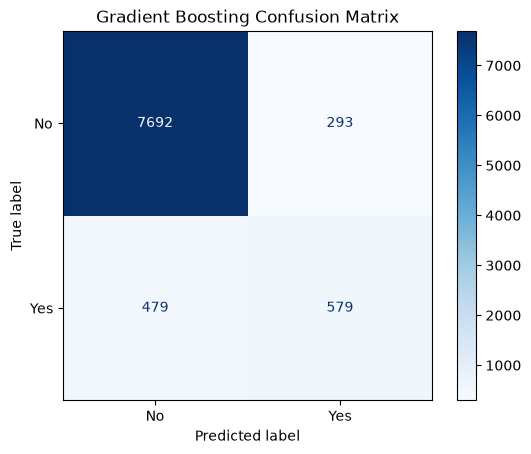

In [12]:
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

#---------- Load data ----------#
X_train = pd.read_csv('X_train.csv')
X_test = pd.read_csv('X_test.csv')

y_train = pd.read_csv('y_train.csv').squeeze()
y_test = pd.read_csv('y_test.csv').squeeze()

#---------- Parameter tuning ----------#
param_grid = {
    'n_estimators': [50, 100, 200],
    'learning_rate': [0.01, 0.1, 0.5],
    'max_depth': [3, 5]
}

grid = GridSearchCV(
    estimator=GradientBoostingClassifier(
        random_state=42
    ),
    param_grid=param_grid,
    cv=5,
    scoring='f1',
    n_jobs=-1
)

grid.fit(X_train, y_train)

# Best model
best_gb = grid.best_estimator_

print("Best Parameters")
print(grid.best_params_)

print(f"Best CV F1 Score: {grid.best_score_:.4f}")

#---------- Predict ----------#
y_pred = best_gb.predict(X_test)

# Metrics
print("\n===== Test Result =====")
print(f"Accuracy  : {accuracy_score(y_test, y_pred):.4f}")
print(f"Precision : {precision_score(y_test, y_pred):.4f}")
print(f"Recall    : {recall_score(y_test, y_pred):.4f}")
print(f"F1-Score  : {f1_score(y_test, y_pred):.4f}")

#---------- Confusion Matrix ----------#
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=['No', 'Yes']
)

disp.plot(cmap='Blues')
plt.title('Gradient Boosting Confusion Matrix')
plt.show()

---